# Simulação das carteiras, benchmarks, risco e gráficos

Esta parte usa as carteiras já escolhidas em `Algoritimos.ipynb` (formação 2017–2019) e só olha preços **a partir da data de entrada**, o último pregão da formação. Nada aqui altera a seleção. As carteiras são *buy-and-hold*, pesos iniciais iguais, sem rebalanceamento, sem custos e com preços ajustados do Yahoo (proventos incluídos).

In [3]:
# Bibliotecas e funcoes de simulacao (simulacao.py na mesma pasta).
import numpy as np
import pandas as pdBB
import matplotlib.pyplot as plt
from IPython.display import display
from simulacao import *

Carregamos os objetos do notebook de algoritmos (`df`, `acoes_elegiveis`, `mst_kruskal`, `carteira_periferica`, `carteira_central`, `parametros`).

In [4]:
# Executa o notebook de algoritmos para disponibilizar os objetos.
%run ./Algoritimos.ipynb

Formacao: 2017-01-01 a 2019-12-31
Avaliacao: 2020-01-01 a 2022-12-31
Formacao da MST: 2017-01-01 ate 2019-12-31
Avaliacao financeira (outro integrante): 2020-01-01 ate 2022-12-31
Pasta da coleta: C:\Users\d3sert\Documents\Anti-crisis-stocks-using-graphs\dados\pandemia
Coleta local encontrada; a celula de dados verificara sua integridade.
Coleta local carregada: dados\pandemia\acoes.csv
Data da coleta (UTC): 2026-11-17T01:35:42.609809+00:00


c:\Users\d3sert\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)
c:\Users\d3sert\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


Situacao
Elegivel    275
Excluida    102
Pendente      2
Name: count, dtype: int64


,Primeiro_preco_na_formacao,Ultimo_preco_na_formacao,Historico_no_inicio,Preco_na_ultima_sessao,Retornos_validos,Sessoes_referencia,Cobertura,Variancia,Precos_invalidos,Situacao,Motivo
Ticker,,,,,,,,,,,
AALR3.SA,2017-01-02,2019-12-30,True,True,748,748,1.00000,0.000274,0,Elegivel,Atende aos criterios observaveis na base.
ABCB4.SA,2017-01-02,2019-12-30,True,True,748,748,1.00000,0.000294,0,Elegivel,Atende aos criterios observaveis na base.
ABEV3.SA,2017-01-02,2019-12-30,True,True,748,748,1.00000,0.000194,0,Elegivel,Atende aos criterios observaveis na base.
AERI3.SA,NaT,NaT,False,False,0,748,0.00000,NaN,0,Excluida,Menos de dois retornos validos; Cobertura abai...
AFLT3.SA,2017-01-02,2019-12-30,True,True,748,748,1.00000,0.004316,0,Elegivel,Atende aos criterios observaveis na base.
...,...,...,...,...,...,...,...,...,...,...,...
WHRL4.SA,2017-01-02,2019-12-30,True,True,748,748,1.00000,0.000705,0,Elegivel,Atende aos criterios observaveis na base.
WIZC3.SA,2017-01-02,2019-12-30,True,True,748,748,1.00000,0.000716,0,Elegivel,Atende aos criterios observaveis na base.
WLMM3.SA,2017-07-07,2019-12-30,False,True,619,748,0.82754,0.001762,0,Excluida,Cobertura abaixo do minimo; Sem evidencia de n...


Arestas Kruskal: 274
Peso total Kruskal: 310.4498719373967


,Vertice,Ticker,Grau,Excentricidade,Folha,Centro
90,90,CYRE3.SA,12,13.952996,False,True
177,177,MULT3.SA,10,13.960034,False,False
117,117,EZTC3.SA,2,14.730801,False,False
116,116,EVEN3.SA,3,14.835683,False,False
159,159,LREN3.SA,6,14.840392,False,False
...,...,...,...,...,...,...
62,62,CEEB3.SA,1,25.681503,True,False
137,137,HBTS5.SA,1,25.747223,True,False
63,63,CEED3.SA,2,25.752772,False,False
175,175,MTSA3.SA,1,27.025550,True,False


... (10 outputs left out)

,Vertice,Ticker,Grau,Excentricidade,Folha,Centro
70,70,GGBR4.SA,5,9.108392,False,True
72,72,GOAU4.SA,3,9.624039,False,False
141,141,USIM5.SA,13,9.691794,False,False
69,69,GGBR3.SA,1,9.951282,True,False
105,105,PETR4.SA,5,10.065092,False,False
98,98,MWET4.SA,3,10.355875,False,False
43,43,CSNA3.SA,2,10.465366,False,False
71,71,GOAU3.SA,1,10.625383,True,False


,Vertice,Ticker,Grau,Excentricidade,Folha,Centro
102,102,PCAR3.SA,1,17.931582,True,False
144,144,VULC3.SA,1,17.931582,True,False
96,96,MSPA3.SA,1,17.888186,True,False
91,91,MAPT4.SA,1,16.993741,True,False
35,35,CLSC3.SA,2,16.621895,False,False
83,83,JFEN3.SA,1,16.594961,True,False
11,11,BGIP3.SA,1,16.594355,True,False
85,85,KEPL3.SA,3,16.558067,False,False


Referencia de 2008: lista de dividendos publicada em 28/12/2006
Fonte: https://www.infomoney.com.br/mercados/em-2006-quem-investiu-em-boas-pagadoras-de-proventos-nao-tem-do-que-reclamar/
Papeis da referencia fora da MST: ['TLPP4.SA', 'CLSC6.SA', 'BRTP4.SA', 'BRTO4.SA', 'TMAR5.SA', 'TRPL4.SA', 'PTIP4.SA', 'ACES4.SA', 'CRUZ3.SA', 'UBBR11.SA', 'TMCP4.SA']


,Empresa,Ticker,Segmento
0,Cemig,CMIG3.SA,Energia eletrica
1,CSN,CSNA3.SA,Siderurgia
2,Comgas,CGAS5.SA,Distribuicao de gas
3,Banco do Brasil,BBAS3.SA,Bancos
4,Sabesp,SBSP3.SA,Saneamento
5,Usiminas,USIM5.SA,Siderurgia
6,Gerdau Metalurgica,GOAU4.SA,Siderurgia
7,Petrobras,PETR4.SA,Petroleo e gas


Definimos as carteiras com os tickers já escolhidos e pesos iguais. A tabela mostra a liquidez mediana na formação de cada ativo e se A e B se sobrepõem. Ações pouco líquidas têm correlações pouco confiáveis por causa de dias sem negociação, e isso pode inflar a periferia da MST.

In [5]:
# Carteiras A e B vindas da selecao; sem dados de teste.
carteiras = {
    'A - Periferica': carteira_periferica['Ticker'].tolist(),
    'B - Central': carteira_central['Ticker'].tolist(),
    'C - Controle': carteira_controle['Ticker'].tolist()
}

liquidez = liquidez_formacao(df, inicio_formacao, fim_formacao)
comp = composicao(carteiras, liquidez)
display(comp)

,Carteira,Ticker,Peso inicial,Liquidez mediana na formacao (R$/dia)
0,A - Periferica,DOHL4.SA,0.125,5.993639e+02
1,A - Periferica,MTSA3.SA,0.125,0.000000e+00
2,A - Periferica,CEED3.SA,0.125,0.000000e+00
3,A - Periferica,HBTS5.SA,0.125,0.000000e+00
4,A - Periferica,CEEB3.SA,0.125,0.000000e+00
5,A - Periferica,CTSA3.SA,0.125,2.913170e+03
6,A - Periferica,RPAD3.SA,0.125,0.000000e+00
7,A - Periferica,SOND5.SA,0.125,0.000000e+00
8,B - Central,CYRE3.SA,0.125,2.189406e+07
9,B - Central,MULT3.SA,0.125,4.371183e+07


Normalizamos os preços pelo fechamento de entrada e calculamos o valor de cada carteira (base 1). Ações sem preço após alguma data ficam congeladas no último preço válido, como se tivessem sido vendidas a ele com caixa rendendo zero.

In [7]:
# Trajetorias a partir do ultimo pregao da formacao.
norm, data_entrada = trajetorias_normalizadas(df['Close'], fim_formacao, fim_avaliacao)
print('Entrada:', data_entrada.date(), '| ultimo pregao:', norm.index[-1].date())

faltando = {n: [t for t in ts if t not in norm.columns] for n, ts in carteiras.items()}
print('Tickers sem preco na entrada:', faltando)

valores = pd.DataFrame({n: valor_buy_and_hold(norm, ts) for n, ts in carteiras.items()})

Entrada: 2019-12-30 | ultimo pregao: 2022-12-29
Tickers sem preco na entrada: {'A - Periferica': [], 'B - Central': [], 'C - Controle': []}


Benchmarks. **Universo EW** é a média equiponderada, *buy-and-hold*, de todas as ações elegíveis, com os mesmos preços ajustados. **Ibovespa** é lido de `dados/pandemia/ibov.csv` ou baixado via `yfinance`. Ele é índice de preço, então a comparação com as ações ajustadas subestima o retorno do índice. O universo EW herda viés de sobrevivência, pois a lista de ações vem das cotadas hoje.

In [8]:
# Benchmarks.
valores['Universo EW'] = norm[acoes_elegiveis].mean(axis=1)
ibov = carregar_ibov(parametros['pasta_coleta'], norm.index)
if ibov is not None:
    valores['Ibovespa'] = ibov
ref = 'Ibovespa' if 'Ibovespa' in valores else 'Universo EW'
print('Referencia para beta e janela de crise:', ref)

Referencia para beta e janela de crise: Ibovespa


A janela de crise é o trecho pico-vale da **referência** dentro de 2020, calculado dos dados e igual para todas as estratégias. Ela é descritiva e não participa da seleção. Reportamos também a avaliação completa e o ano de 2020.

In [9]:
# Janelas de avaliacao.
ano_crise = pd.Timestamp(inicio_avaliacao).year
janelas, crise = definir_janelas(valores[ref], inicio_avaliacao, fim_avaliacao, ano_crise)
for nome, j in janelas.items():
    print(nome)

Avaliacao completa
Ano 2020
Crise (23/01/2020 a 23/03/2020)


Métricas por janela. A principal é o **máximo drawdown**. Volatilidade é anualizada com 252 pregões; beta e correlação são em relação à referência.

In [10]:
# Tabela de metricas.
tab = tabela_metricas(valores, janelas, ref=ref)
pd.options.display.float_format = '{:.3f}'.format
display(tab)

Retorno acumulado  \
Janela                          Estrategia                          
Avaliacao completa              A - Periferica              0.382   
                                B - Central                -0.475   
                                C - Controle               -0.032   
                                Universo EW                 0.226   
                                Ibovespa                   -0.051   
Ano 2020                        A - Periferica              0.223   
                                B - Central                -0.147   
                                C - Controle                0.027   
                                Universo EW                 0.255   
                                Ibovespa                    0.029   
Crise (23/01/2020 a 23/03/2020) A - Periferica             -0.105   
                                B - Central                -0.564   
                                C - Controle               -0.444   
                                Universo EW                -0.407   
                                Ibovespa                   -0.468   

                                                Volatilidade anualizada  \
Janela                          Estrategia                                
Avaliacao completa              A - Periferica                    0.328   
                                B - Central                       0.475   
                                C - Controle                      0.316   
                                Universo EW                       0.239   
                                Ibovespa                          0.309   
Ano 2020                        A - Periferica                    0.448   
                                B - Central                       0.616   
                                C - Controle                      0.449   
                                Universo EW                       0.347   
                                Ibovespa                          0.447   
Crise (23/01/2020 a 23/03/2020) A - Periferica                    0.347   
                                B - Central                       0.989   
                                C - Controle                      0.865   
                                Universo EW                       0.527   
                                Ibovespa                          0.840   

                                                Max drawdown  \
Janela                          Estrategia                     
Avaliacao completa              A - Periferica         0.338   
                                B - Central            0.591   
                                C - Controle           0.462   
                                Universo EW            0.407   
                                Ibovespa               0.468   
Ano 2020                        A - Periferica         0.198   
                                B - Central            0.573   
                                C - Controle           0.462   
                                Universo EW            0.407   
                                Ibovespa               0.468   
Crise (23/01/2020 a 23/03/2020) A - Periferica         0.185   
                                B - Central            0.564   
                                C - Controle           0.462   
                                Universo EW            0.407   
                                Ibovespa               0.468   

                                                Pior retorno diario  \
Janela                          Estrategia                            
Avaliacao completa              A - Periferica               -0.083   
                                B - Central                  -0.175   
                                C - Controle                 -0.157   
                                Universo EW                  -0.098   
                                Ibovespa                     -0.148   
Ano 2020    

Controle com carteiras aleatórias: 2000 sorteios de 8 ações do universo elegível, pesos iguais, mesma regra de simulação. A tabela mostra qual fração dos sorteios teve risco menor ou igual ao de cada estratégia. Valores próximos de 0,5 significam que a estratégia é indistinguível do acaso.

In [11]:
# Controle aleatorio (sementes fixas, reprodutivel).
q = len(carteiras['A - Periferica'])
alea = carteiras_aleatorias(norm, acoes_elegiveis, q, janelas, n=2000)
estrategias = list(carteiras)
pos = posicao_nas_aleatorias(tab, alea, estrategias)
display(pos) 

Prop. aleatorias com Max drawdown <= estrategia  \
Janela                          Estrategia                                                        
Avaliacao completa              A - Periferica                                            0.071   
                                B - Central                                               0.851   
                                C - Controle                                              0.466   
Ano 2020                        A - Periferica                                            0.003   
                                B - Central                                               0.922   
                                C - Controle                                              0.634   
Crise (23/01/2020 a 23/03/2020) A - Periferica                                            0.004   
                                B - Central                                               0.982   
                                C - Controle                                              0.729   

                                                Prop. aleatorias com Volatilidade anualizada <= estrategia  
Janela                          Estrategia                                                                  
Avaliacao completa              A - Periferica                                              0.529           
                                B - Central                                                 0.836           
                                C - Controle                                                0.483           
Ano 2020                        A - Periferica                                              0.698           
                                B - Central                                                 0.887           
                                C - Controle                                                0.703           
Crise (23/01/2020 a 23/03/2020) A - Periferica                                              0.025           
                                B - Central                                                 1.000           
                                C - Controle                                                0.980

Gráficos: MST com A e B destacadas, evolução patrimonial, drawdown, métricas por janela e posição nas carteiras aleatórias. A faixa cinza marca a janela de crise.

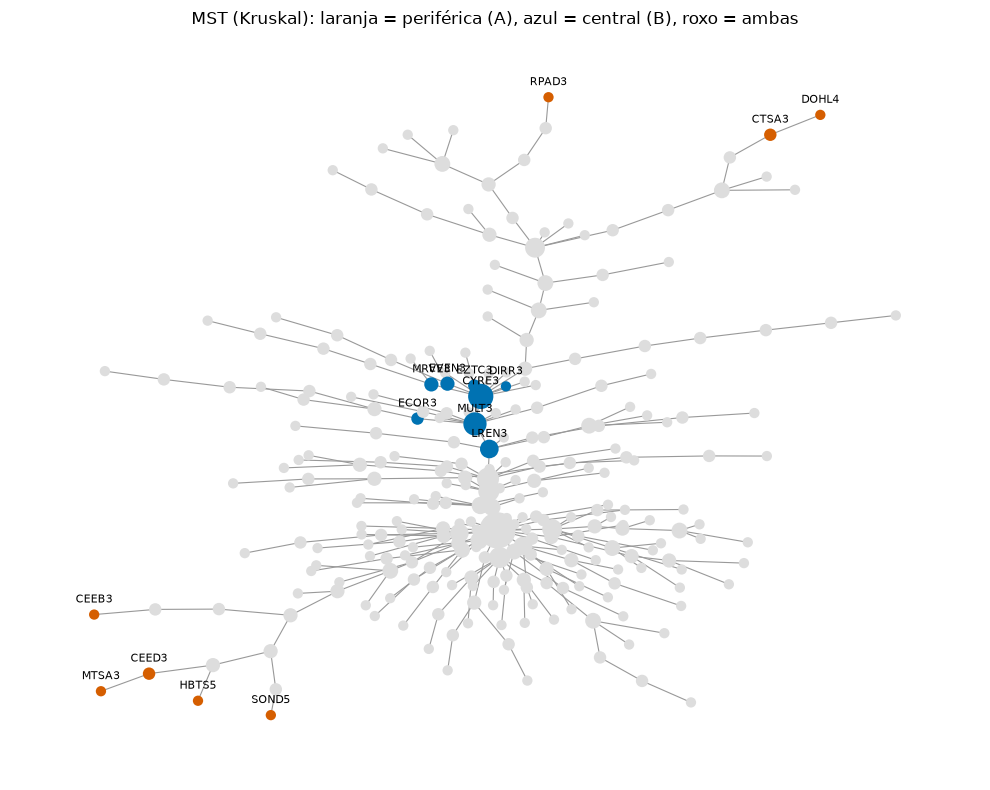

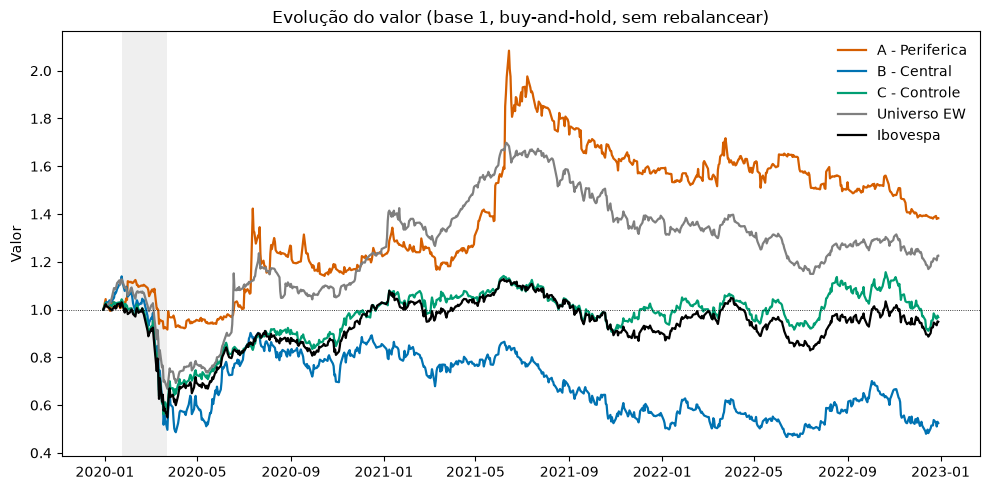

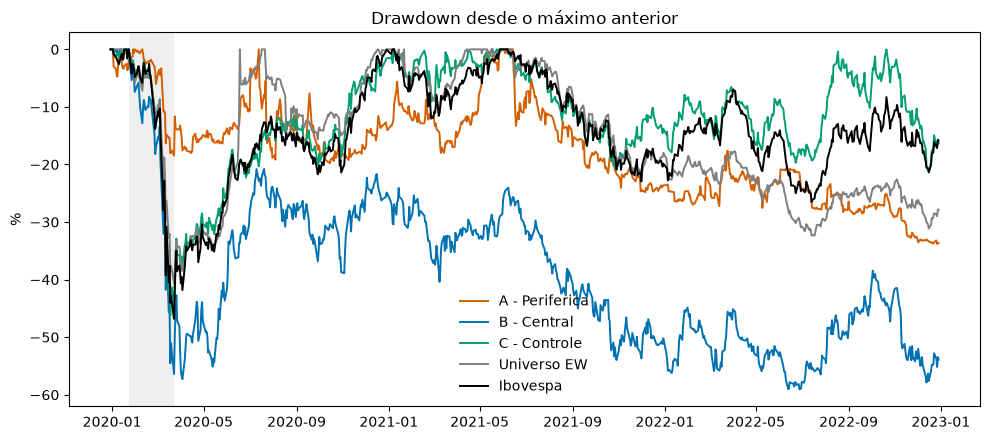

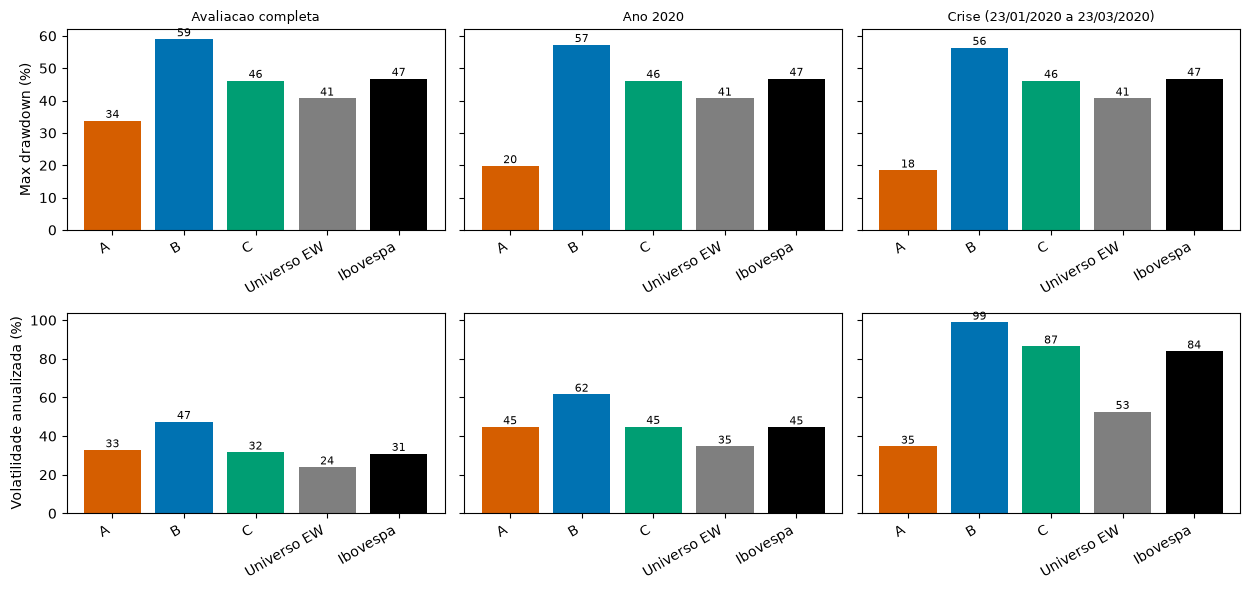

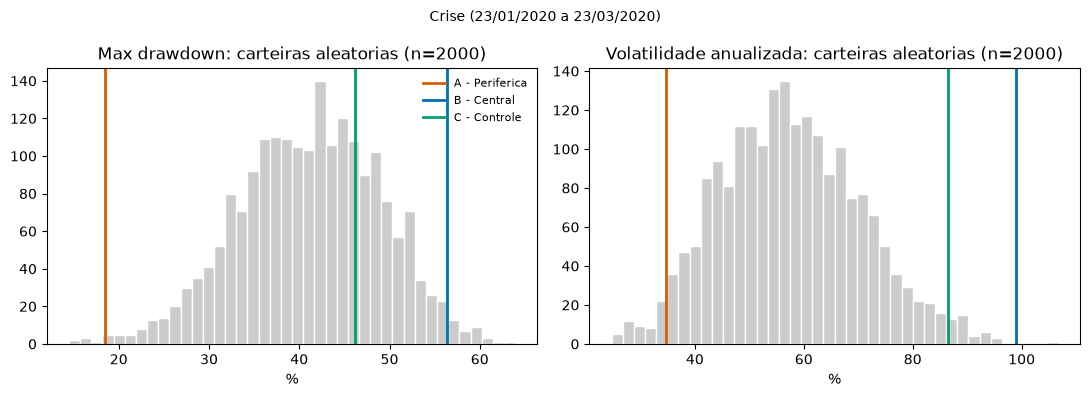

In [12]:
# Figuras salvas em results/figures.
pasta_fig = Path('results/figures'); pasta_fig.mkdir(parents=True, exist_ok=True)
tickers_mst = list(matriz_mantegna_formacao.columns)
fig_mst(mst_kruskal, tickers_mst, set(carteiras['A - Periferica']),
        set(carteiras['B - Central']), pasta_fig / 'mst_carteiras.png')
fig_evolucao(valores, crise, pasta_fig / 'evolucao.png')
fig_drawdown(valores, crise, pasta_fig / 'drawdown.png')
fig_metricas(tab, pasta_fig / 'metricas.png')
jan_crise = list(janelas)[-1]
fig_aleatorias(alea, tab, jan_crise, estrategias, pasta_fig / 'aleatorias_crise.png')
plt.show()

In [13]:
salvar('results', valores, tab, pos, comp)